# Pipeline walkthrough (PG-S2-32, prototype)

This notebook runs the integrated pipeline and shows what goes in, what each stage does, and what comes out. RYA's statistical core (response model, ρ, d̂, the minimal-effects framing and EXP002) is **not changed**; the pipeline adds screening, a fallback, uncertainty reporting and a compressed network around it.

**How to run**
1. Same environment as the baseline walkthrough: kernel **Python (scrp)**. The pipeline adds one package, `scipy` (now in `requirements.txt`; run `pip install scipy` or `conda env update -f environment.yml`).
2. Open from the repo root, on branch `pipeline-demo` / `integration`.
3. *Restart* → *Run All*. About 1 minute.

**What the data is.** Ten synthetic comparisons built to exercise each objective, plus one real RYA training instance. No RY25 survey responses are used.

| Section | Stage | Objective · owner | Module |
|---|---|---|---|
| 1 | Set-up | | `pipeline/run.py` |
| 2 | Input cases | | `pipeline/scenarios.py` |
| 3a | ρ validation | O1 · SIN-WEI | `pipeline/screen.py` |
| 3b | Boundary pair | RYA method (provisional) | `pipeline/boundary.py` |
| 3c | Screening | O1 · SIN-WEI | `pipeline/screen.py` + `o1/` |
| 3d | Null distribution | O4 · Murat (network), O2 · Shuyun (fallback) | `pipeline/nulls.py` + `o2/` |
| 3e | Minimal-effects test | RYA method | `pipeline/boundary.py` |
| 3f | ρ uncertainty | O3 · Pratik | `pipeline/uncertainty.py` + `o3/` |
| 4 | All cases: original path vs pipeline vs truth | | `pipeline/demo.py` |
| 5 | Benchmark | | `pipeline/benchmark.py` |
| 6 | Bayesian analogue (evaluation only) | O3 · Pratik | `pipeline/bayes_eval.py` |

## 1. Set-up

The pipeline is one object. `build_pipeline` loads EXP002 (ONNX) and SIN-WEI's detector and holds the settings. The data folder comes from `settings.py` exactly as in the baseline walkthrough (`SCRP_DATA` → `local_settings.py` → `./data`).

```
request (counts X, Y + ρ)
  → 1a ρ validation → boundary pair → 1b screening (both pairs)
       PASS    → 2a EXP002 network  → Gamma(shape, rate)
       FLAGGED → 2b simulated null  → Monte Carlo empirical tail
  → 3 minimal-effects test → 3+ ρ uncertainty
  → result: decision · p-value · p-range · flag (GREEN / AMBER / RED)
```

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

from scrp_toolkit.config import default_project_root, resolve_project_paths
from scrp_toolkit.pipeline.run import build_pipeline, Pipeline, PipelineConfig
from scrp_toolkit.pipeline.scenarios import build_scenarios

pd.set_option("display.max_colwidth", 70, "display.width", 200)
ROOT = default_project_root()
EPSILON = 0.1                     # placeholder until RYA confirms the production value

pl = build_pipeline(ROOT)         # robust pipeline, default settings
import os; print("Data folder:", os.path.relpath(ROOT))
print(pl.net.predictor.describe())
print(pl.cfg)

Data folder: data
Model: 20 layers, width 256, 40 features, P_transform='all_P_asymm'
PipelineConfig(mode='robust', test_mode='boundary', weights='fp32', fallback_method='mc_empirical', fallback_draws=4000, uncertainty=True, rho_delta=0.05, uncertainty_draws=1500, screen_threshold=None, small_group_n=30, small_group_ratio=20.0)


## 2. The input cases

Each case is a `ComparisonRequest`: answer counts for options 1–4 in group X and group Y, the item's 4×4 unreliability matrix ρ, and ε. The table shows what each case is meant to exercise and what should happen.

In [2]:
paths = resolve_project_paths(ROOT)
scenarios = build_scenarios(pl.net.predictor.p_matrices, paths.instance_dir, EPSILON)
pd.DataFrame([{
    "case": s.name, "tests": s.objective, "item": s.request.item,
    "X counts": [int(v) for v in s.request.x], "Y counts": [int(v) for v in s.request.y],
    "n_X": int(s.request.x.sum()), "n_Y": int(s.request.y.sum()),
    "expected": s.expect} for s in scenarios])

,case,tests,item,X counts,Y counts,n_X,n_Y,expected
0,A. Typical comparison,O4 network + O3 range,ry9,"[40, 52, 7, 14]","[9, 17, 54, 12]",113,92,PASS -> network Gamma -> GREEN
1,B. Classroom (n=8) vs national,O1 screening + O2 fallback,ry9,"[2, 1, 2, 3]","[1800, 2880, 2520, 1800]",8,9000,FLAGGED -> simulated null -> AMBER; network alone calls a false 'm...
2,C. Classroom (n=25) vs national,O1 screening,ry9,"[3, 6, 10, 6]","[1800, 2880, 2520, 1800]",25,9000,classifier alone passes it (O1 gap); the small-group rule sends it...
3,D. Everyone gave one answer,O1 degeneracy safeguard,ry9,"[0, 0, 12, 0]","[30, 41, 25, 14]",12,110,FLAGGED (degenerate) -> fallback -> AMBER
4,E. Corrupt rho (row sums 1.06),O1 rho validation,ry9,"[40, 52, 7, 14]","[9, 17, 54, 12]",113,92,"REJECT -> RED, no p-value"
5,F. Six-option item,O1 scope check,chs1,"[3, 4, 5, 6]","[6, 5, 4, 3]",18,18,REJECT -> RED
6,"G. Cohort above training range (n=15,000)",O1 training-range check,ry9,"[2700, 4950, 4350, 3000]","[1800, 2880, 2520, 1800]",15000,9000,"FLAGGED (outside 5-9,940) -> fallback"
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",O3 rho uncertainty,ry9,"[24, 33, 24, 19]","[14, 30, 34, 22]",100,100,wide p-range; AMBER if the decision flips
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",O3 rho uncertainty,ry9,"[24, 33, 24, 19]","[14, 30, 34, 22]",100,100,narrow p-range; GREEN
9,"J. RYA training instance n=6 vs 5,215 (ry24)",O1 acceptance case (SIN-WEI),ry24,"[3, 1, 1, 1]","[979, 1468, 900, 1868]",6,5215,FLAGGED by classifier -> fallback


## 3. One case, stage by stage

Case **B**: a classroom of 8 students against a national cohort of 9,000 on item `ry9`. This is the situation the project was set up for: extreme group-size imbalance, where EXP002's Gamma approximation fails silently.

In [3]:
req = next(s.request for s in scenarios if s.name.startswith("B."))
print("item", req.item, "| X =", req.x.astype(int), "| Y =", req.y.astype(int), "| epsilon =", req.epsilon)
print("rho (row = latent type, column = answer given):")
pd.DataFrame(req.P, index=[f"type {i}" for i in range(1, 5)], columns=[f"ans {i}" for i in range(1, 5)]).round(3)

item ry9 | X = [2 1 2 3] | Y = [1800 2880 2520 1800] | epsilon = 0.1
rho (row = latent type, column = answer given):


,ans 1,ans 2,ans 3,ans 4
type 1,0.43,0.41,0.10,0.06
type 2,0.05,0.57,0.28,0.10
type 3,0.01,0.12,0.61,0.27
type 4,0.01,0.02,0.16,0.81


### 3a. ρ validation (Objective 1, SIN-WEI)

Before anything is computed, ρ must be usable: 4×4, finite, non-negative, each row summing to 1 within 0.02 (the JSON values are rounded, so small deviations are a warning, not an error). Six-option `chs` items are rejected because no model exists for them. A rejected request stops here with a **RED** flag and no p-value.

In [4]:
from scrp_toolkit.pipeline.screen import validate_rho
rc = validate_rho(req)
rc

RhoCheck(status='warn', reasons=('rho row sums rounded (max error 0.010); kept as given',), max_row_sum_error=0.010000000000000009, certainty=2.42, asymmetry=0.030716666666666666)

### 3b. Boundary pair (RYA's method, provisional)

The test is H0: d_norm < ε (no meaningful difference). The null distribution is evaluated where H0 is hardest to reject: the **boundary pair**, built by shrinking both groups' answer shares toward their midpoint until d_norm = ε exactly. Group sizes n and m do not change.

d_norm is RYA's scaled d̂: a Mahalanobis-style distance between the two groups' shares, using the covariance implied by ρ, multiplied by ½(1/n + 1/m).

*Provisional:* this follows the draft paper. The portal's JavaScript has not been received; `test_mode="point_null"` gives Murat's ε = 0 stand-in instead.

In [5]:
from scrp_toolkit.pipeline.boundary import find_boundary
bp = find_boundary(req)
print(f"observed d_norm = {bp.d_norm_observed:.4f}   boundary d_norm = {bp.d_norm_boundary:.4f}   shrink = {bp.shrink:.3f}   ({bp.note})")
pd.DataFrame({"observed X": req.x, "boundary X": np.round(bp.x, 2),
              "observed Y": req.y, "boundary Y": np.round(bp.y, 1)}, index=[f"answer {i}" for i in range(1, 5)])

observed d_norm = 0.2215   boundary d_norm = 0.1000   shrink = 0.681   (shrunk toward midpoint)


,observed X,boundary X,observed Y,boundary Y
answer 1,2.0,1.94,1800.0,1871.7
answer 2,1.0,1.25,2880.0,2600.3
answer 3,2.0,2.04,2520.0,2477.0
answer 4,3.0,2.78,1800.0,2051.0


### 3c. Screening (Objective 1, SIN-WEI)

Decides whether EXP002's Gamma can be trusted for this request. Checks, any of which routes the request to the fallback (**FLAGGED**):

* SIN-WEI's compatibility classifier (logistic regression, 54 features, threshold 0.10), run on the **observed** pair and on the **boundary** pair that actually reaches the network;
* her degeneracy safeguard (a group answering all in one category);
* group sizes outside EXP002's training range (5–9,940);
* the small-group rule added after validation: a group under 30 compared with one at least 20× larger.

In [6]:
from scrp_toolkit.pipeline.screen import screen
sr = screen(req, rc, bp, pl.gate)
print("route:", sr.route)
print(f"P(incompatible): observed pair {sr.p_incompatible_observed:.3f}, boundary pair {sr.p_incompatible_boundary:.3f}, threshold {sr.threshold}")
for r in sr.reasons: print(" -", r)

route: FLAGGED
P(incompatible): observed pair 1.000, boundary pair 1.000, threshold 0.1
 - classifier flags observed pair (p=1.00)
 - classifier flags boundary pair (p=1.00)
 - small group (8) against a group 1125x larger


### 3d. Null distribution: network (O4) vs fallback (O2)

* **2a, EXP002 network (Murat):** predicts Gamma(shape, rate) for d̂ at the boundary pair. Batched inference; fp16 weights optional (2.4 MB, for the browser). The rate is used as-is.
* **2b, simulated fallback (Shuyun):** RYA's own simulator (a vectorised port of `d_hat_simulation_from_LL.R`): fix each group's composition, let every student answer through ρ, compute d̂, repeat 4,000 times. The tail is read off the draws directly (Shuyun's Monte Carlo empirical estimator).

The pipeline only uses the fallback for FLAGGED requests. Both are computed below so they can be compared.

network : Gamma(shape=1.585, rate=19.888)  q95 = 0.204  (94.3 ms)
fallback: 4000 simulated draws                    q95 = 0.674  (15.0 ms)


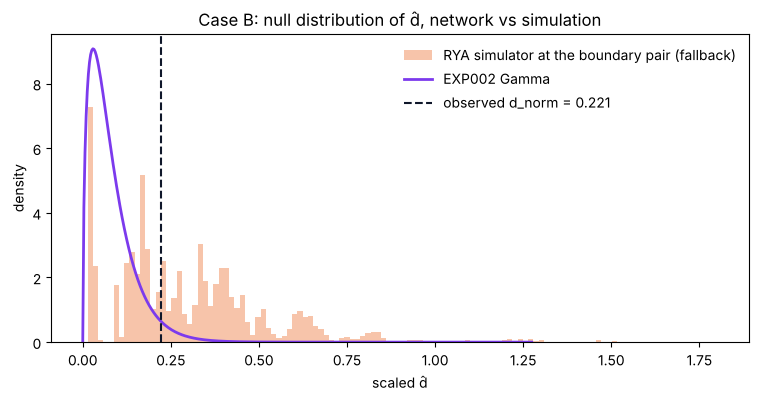

In [7]:
from scrp_toolkit.pipeline.nulls import simulated_null
nn = pl.net(req, bp)              # the first call also builds the batched ONNX session (~0.5 s, once)
fb = simulated_null(req, bp, "mc_empirical", draws=4000)   # same draws and seed as the pipeline uses
print(f"network : Gamma(shape={nn.params['shape']:.3f}, rate={nn.params['rate']:.3f})  q95 = {nn.q95:.3f}  ({nn.time_ms:.1f} ms)")
print(f"fallback: {int(fb.params['n_draws'])} simulated draws                    q95 = {fb.q95:.3f}  ({fb.time_ms:.1f} ms)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(fb.draws, bins=120, density=True, color="#EA580C", alpha=0.35, label="RYA simulator at the boundary pair (fallback)")
xs = np.linspace(0, np.quantile(fb.draws, 0.995), 400)
ax.plot(xs, stats.gamma.pdf(xs, nn.params["shape"], scale=1 / nn.params["rate"]), color="#7C3AED", lw=2, label="EXP002 Gamma")
ax.axvline(bp.d_norm_observed, color="#0F172A", ls="--", label=f"observed d_norm = {bp.d_norm_observed:.3f}")
ax.set_xlabel("scaled d̂"); ax.set_ylabel("density"); ax.set_title("Case B: null distribution of d̂, network vs simulation")
ax.legend(frameon=False); plt.show()

### 3e. Minimal-effects test

p = P(d̂ ≥ observed d̂ | boundary pair). If p < α = 0.05, H0 is rejected: **meaningful difference**. Otherwise: **no meaningful difference shown**. The same test runs on either null distribution; only the null changes.

In [8]:
from scrp_toolkit.pipeline.boundary import minimal_effects_test
t_nn, t_fb = minimal_effects_test(req, bp, nn), minimal_effects_test(req, bp, fb)
pd.DataFrame([{"null": "EXP002 network (original path)", "p-value": round(t_nn.p_value, 4), "decision": t_nn.decision},
              {"null": "simulated fallback (pipeline)", "p-value": round(t_fb.p_value, 4), "decision": t_fb.decision}])

,null,p-value,decision
0,EXP002 network (original path),0.0366,meaningful difference
1,simulated fallback (pipeline),0.5609,no meaningful difference shown


For case B the simulated distribution is multimodal (a class of 8 can only produce a few distinct answer patterns), which is exactly the situation where a single Gamma fails. The network's Gamma is far too narrow (compare the plot above), so the original path reports a "meaningful difference" that the simulation does not support. Screening sends this case to the fallback, so the pipeline reports the simulated p-value instead.

### 3f. ρ uncertainty (Objective 3, Pratik)

ρ is estimated from test-retest data, but the method treats it as known. The pipeline re-runs the whole test (boundary pair, observed d̂, null, p-value) for plausible alternative ρ matrices and reports the spread:

* with genuine test-retest counts: draws from a Dirichlet posterior on each row of ρ (Pratik's `_sample_rho`);
* without them (as here): Pratik's ±5% off-diagonal error-mass perturbation.

The decision is **stable** if every variant lands on the same side of α.

In [9]:
res = pl.run(req)
u = res.uncertainty
print(f"source: {u.source} ({u.n_variants} variants)")
print(f"p-value {res.p_value:.4f}, range {u.p_low:.4f} to {u.p_high:.4f}, decision stable: {u.decision_stable}")

source: rho error mass +/-5% (4 variants)
p-value 0.5609, range 0.5243 to 0.5809, decision stable: True


### Final result

What a user of the portal would see. **GREEN**: screening passed and the decision is stable. **AMBER**: the fallback was used or the decision flips within the ρ range. **RED**: rejected, no p-value.

In [10]:
pd.Series(res.summary())

label                                                                 B classroom n=8
item                                                                              ry9
n_X                                                                                 8
n_Y                                                                              9000
route                                                                         FLAGGED
null_method                                                              mc_empirical
d_hat_norm                                                                     0.2215
epsilon                                                                           0.1
p_value                                                                        0.5609
p_range                                                              (0.5243, 0.5809)
shape_range                                                                      None
rate_range                                            

## 4. All cases: original path vs pipeline vs truth

Every case runs through:
* the **original path** (`mode="direct"`): straight to EXP002, no checks;
* the **pipeline**;
* **truth**: RYA's simulator at the same boundary pair with 20,000 draws.

Note the truth and the fallback share the simulator (with different random seeds), so this shows how far the network path is from RYA's own model; it does not test the model itself.

In [11]:
from scrp_toolkit.pipeline.demo import run_demo
demo = run_demo(ROOT, EPSILON)
fmt = lambda v: "-" if v is None or (isinstance(v, float) and not np.isfinite(v)) else f"{v:.3f}"
view = demo[["scenario", "n_X", "n_Y", "route", "null", "p_direct", "p_robust", "p_truth", "p_range", "flag"]].copy()
for c in ("p_direct", "p_robust", "p_truth"): view[c] = view[c].map(fmt)
view["p_range"] = view["p_range"].map(lambda v: "-" if v is None else f"{v[0]:.3f}-{v[1]:.3f}")
view

,scenario,n_X,n_Y,route,null,p_direct,p_robust,p_truth,p_range,flag
0,A. Typical comparison,113,92,PASS,nn_fp32,0.000,0.000,0.000,0.000-0.000,GREEN
1,B. Classroom (n=8) vs national,8,9000,FLAGGED,mc_empirical,0.037,0.561,0.551,0.524-0.581,AMBER
2,C. Classroom (n=25) vs national,25,9000,FLAGGED,mc_empirical,0.137,0.334,0.338,0.327-0.347,AMBER
3,D. Everyone gave one answer,12,110,FLAGGED,mc_empirical,0.000,0.000,0.000,0.000-0.001,AMBER
4,E. Corrupt rho (row sums 1.06),113,92,REJECT,NaN,0.000,-,-,-,RED
5,F. Six-option item,18,18,REJECT,NaN,1.000,-,-,-,RED
6,"G. Cohort above training range (n=15,000)",15000,9000,FLAGGED,mc_empirical,1.000,1.000,1.000,1.000-1.000,AMBER
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",100,100,PASS,nn_fp32,0.216,0.216,0.218,0.016-0.525,AMBER
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",100,100,PASS,nn_fp32,0.216,0.216,0.218,0.187-0.226,GREEN
9,"J. RYA training instance n=6 vs 5,215 (ry24)",6,5215,FLAGGED,mc_empirical,0.087,0.360,0.353,0.334-0.376,AMBER


**Reading the table**
* **A**: normal comparison. Screening passes, the network is used, GREEN.
* **B, C, J**: small classrooms against large groups. The original path's p-values are far below the truth (B even crosses α = 0.05: a false "meaningful difference"). The pipeline routes them to the fallback and matches the truth. C is passed by the classifier and caught by the small-group rule.
* **D, G**: a group answering in one category, and a cohort above the training range. Both are flagged and use the fallback.
* **E, F**: invalid ρ and a six-option item. The original path still returns a number; the pipeline refuses (RED).
* **H vs I**: the same comparison with ρ estimated from a small (15 per row) or large (2,000 per row) synthetic retest study. The p-value is the same, but the small study's p-range crosses α, so H is AMBER and I is GREEN.

Why each case was flagged:

In [12]:
demo[["scenario", "flag", "why"]]

,scenario,flag,why
0,A. Typical comparison,GREEN,rho row sums rounded (max error 0.010); kept as given
1,B. Classroom (n=8) vs national,AMBER,classifier flags observed pair (p=1.00); classifier flags boundary...
2,C. Classroom (n=25) vs national,AMBER,small group (25) against a group 360x larger; fallback null (mc_em...
3,D. Everyone gave one answer,AMBER,observed group answers all in one category; classifier flags obser...
4,E. Corrupt rho (row sums 1.06),RED,rho row sums off by up to 0.060 (limit 0.02)
5,F. Six-option item,RED,six-option chs item: no model exists for it
6,"G. Cohort above training range (n=15,000)",AMBER,group sizes 15000/9000 outside training range 5-9940; fallback nul...
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",AMBER,decision flips within rho uncertainty (p 0.016-0.525); rho row sum...
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",GREEN,rho row sums rounded (max error 0.010); kept as given
9,"J. RYA training instance n=6 vs 5,215 (ry24)",AMBER,classifier flags observed pair (p=1.00); classifier flags boundary...


## 5. Benchmark: 400 synthetic comparisons

Comparisons drawn across four group-size ratio bands on the 53 four-option items. For each: the original path's and the pipeline's p-values against the truth (10,000 simulated draws). About 20 seconds.

In [13]:
from scrp_toolkit.pipeline.benchmark import run_benchmark, summarise
bench = run_benchmark(ROOT, n_cases=400)
summarise(bench).T

,1-2x,2-10x,10-100x,100-2000x,all
cases,100.000,100.000,100.000,100.000,400.000
flagged_%,0.000,0.000,5.000,88.000,23.250
direct_no_answer,0.000,0.000,0.000,0.000,0.000
direct_agree_%,98.000,96.000,97.000,89.000,95.000
direct_false_pos,0.000,0.000,0.000,8.000,8.000
direct_median_abs_p_err,0.000,0.000,0.009,0.111,0.006
direct_median_ms,4.284,4.319,4.208,4.075,4.222
robust_no_answer,0.000,0.000,0.000,0.000,0.000
robust_agree_%,98.000,96.000,97.000,98.000,97.250
robust_false_pos,0.000,0.000,0.000,0.000,0.000


Below 100× the two configurations agree with the truth equally often (96–98%), because screening passes almost everything and both use the network. At 100× and above, the original path agrees 89% of the time with 8 false positives; the pipeline agrees 98% with none. In that band the pipeline takes about 4-5× as long per comparison as the original path (the fallback simulation), still tens of milliseconds.

## 6. Bayesian analogue (Objective 3, evaluation only)

Pratik's Bayesian version of the question: a Dirichlet posterior on each group's answer shares, pushed through d_norm, gives P(d_norm > ε | data). Here it is called "meaningful" when that probability is at least 0.95. His functions are imported unchanged from `pipeline/o3/`. It is **not** on the deployed path; it is shown beside the pipeline's decision.

In [14]:
from scrp_toolkit.pipeline.bayes_eval import compare_demo
bayes = compare_demo(ROOT, EPSILON)
b = bayes[["scenario", "pipeline_p", "pipeline_decision", "bayes_P_d_gt_eps", "bayes_ci95", "bayes_decision", "agree"]].copy()
b["pipeline_p"] = b["pipeline_p"].map(fmt)
b["bayes_P_d_gt_eps"] = b["bayes_P_d_gt_eps"].map(fmt)
b["bayes_ci95"] = b["bayes_ci95"].map(lambda v: "-" if not isinstance(v, tuple) else f"{v[0]:.3f} to {v[1]:.3f}")
b

,scenario,pipeline_p,pipeline_decision,bayes_P_d_gt_eps,bayes_ci95,bayes_decision,agree
0,A. Typical comparison,0.000,meaningful difference,1.000,0.773 to 1.873,meaningful difference,True
1,B. Classroom (n=8) vs national,0.561,no meaningful difference shown,0.899,0.037 to 1.286,no meaningful difference shown,True
2,C. Classroom (n=25) vs national,0.334,no meaningful difference shown,0.733,0.017 to 0.744,no meaningful difference shown,True
3,D. Everyone gave one answer,0.000,meaningful difference,1.000,0.919 to 4.156,meaningful difference,True
4,E. Corrupt rho (row sums 1.06),-,NaN,-,-,NaN,None
5,F. Six-option item,-,NaN,-,-,NaN,None
6,"G. Cohort above training range (n=15,000)",1.000,no meaningful difference shown,0.000,0.001 to 0.007,no meaningful difference shown,True
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",0.216,no meaningful difference shown,0.699,0.017 to 0.576,no meaningful difference shown,True
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",0.216,no meaningful difference shown,0.627,0.015 to 0.415,no meaningful difference shown,True
9,"J. RYA training instance n=6 vs 5,215 (ry24)",0.360,no meaningful difference shown,0.941,0.060 to 1.010,no meaningful difference shown,True


The two agree on every case that reaches a test. Validation (`python -m scrp_toolkit.pipeline.bayes_eval`) also found that the Bayesian 95% credible intervals cover the true d_norm less often than 95% for small groups (about 51% at 30 vs 30), which has been fed back.

## Settings and caveats

| Setting | Default | Meaning |
|---|---|---|
| `epsilon` | 0.1 | Minimal-effects threshold. **Placeholder** until RYA confirms it. |
| `test_mode` | `"boundary"` | Draft paper's boundary test (provisional). `"point_null"` = ε 0 stand-in. |
| `weights` | `"fp32"` | `"fp16"` = compressed browser model (same decisions in the demo). |
| `fallback_method` | `"mc_empirical"` | Also `"weibull"`, `"gamma_mle"` (compared in `benchmark.compare_fallback_candidates`). |
| `rho_delta` | 0.05 | ρ perturbation size when no test-retest counts are given. |
| `small_group_n` | 30 | Small-group rule; `None` turns it off. |

Example: `build_pipeline(ROOT, weights="fp16", test_mode="point_null", small_group_n=None)`.

**Open points.** The boundary construction is taken from the draft paper until the portal code arrives. Validation found the boundary test calls "meaningful" about 7–8% of the time at nominal 5% under RYA's own model (12% for very small groups); this p-value calibration is for the team and RYA to decide on. See `docs/pipeline.md`.